In [1]:
import sys
import time
from datetime import datetime, timedelta, timezone
from pathlib import Path

import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import plotly.graph_objects as go
from plotly.subplots import make_subplots

sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", "{:,.2f}".format)

# backend/ (the folder that contains app/) goes on the import path, so the shared code in app/ can be imported
BACKEND_DIR = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "app").is_dir())
sys.path.insert(0, str(BACKEND_DIR))

# BTC/USDT trading demo

## Step 1 — Market data

| # | Stage | What happens |
|---|-------|--------------|
| 1 | Fetch | Download raw 1-hour candles from the Binance public API |
| 2 | Inspect | Look at the raw data and see why it can't be used as-is |
| 3 | Clean | Keep the needed columns, fix types and names, run quality checks |
| 4 | Visualize | Candlestick + volume chart, daily overview, summary table |

In [2]:
# Configuration. SYMBOL and INTERVAL come from backend/app/config.py, so the notebook and the backend use the same ones.
from app.config import INTERVAL, SYMBOL   # candle size (INTERVAL): 1m, 5m, 15m, 1h, 4h, 1d ...

LOOKBACK_DAYS = 90                         # how much history to download


## 1. Fetch raw data

Endpoint: `GET /api/v3/klines` ([docs](https://developers.binance.com/docs/binance-spot-api-docs/rest-api/market-data-endpoints#klinecandlestick-data)).
One request returns up to <u>**1000**</u> candles, so `fetch_klines` pages forward until it reaches `end`.

In [3]:
from app.market import fetch_klines   # backend/app/market.py: downloads candles from the public Binance API, MAX_LIMIT per request


In [4]:
end = datetime.now(timezone.utc)   # download time: this computer's clock, not from the API
start = end - timedelta(days=LOOKBACK_DAYS)

raw_rows = fetch_klines(SYMBOL, INTERVAL, start, end)

print(f"Downloaded {len(raw_rows):,} candles for {SYMBOL} ({INTERVAL})")
print("First two rows exactly as the API sends them:")
raw_rows[:2]

Downloaded 2,160 candles for BTCUSDT (1h)
First two rows exactly as the API sends them:


[[1786910400000,
  '63108.80000000',
  '63140.00000000',
  '63027.60000000',
  '63067.79000000',
  '122.98382000',
  1786913999999,
  '7758206.70638790',
  27453,
  '65.68412000',
  '4143086.33520020',
  '0'],
 [1786914000000,
  '63067.79000000',
  '63085.15000000',
  '62754.00000000',
  '62929.61000000',
  '328.59983000',
  1786917599999,
  '20680626.55125850',
  71458,
  '155.77806000',
  '9805116.78984070',
  '0']]

## 2. Inspect raw data

The raw table exactly as the API returns it, before any changes.

In [5]:
# Column names from the Binance docs (backend/app/market.py), kept as-is for the raw table
from app.market import RAW_COLUMNS

raw = pd.DataFrame(raw_rows, columns=RAW_COLUMNS)
# raw.head()
raw.tail()

,open_time,open,high,low,close,volume,close_time,quote_volume,trades,taker_buy_base_volume,taker_buy_quote_volume,ignore
2155,1794668400000,65914.02000000,66047.37000000,65066.66000000,65742.01000000,3041.27366000,1794671999999,199277996.24476340,644684,1369.83076000,89829878.38683800,0
2156,1794672000000,65742.00000000,65747.57000000,65000.00000000,65349.01000000,1749.24546000,1794675599999,114325436.09606330,556879,809.70289000,52940760.99547020,0
2157,1794675600000,65349.00000000,66189.88000000,65070.32000000,65901.60000000,1284.51004000,1794679199999,84251087.76400900,427748,598.20125000,39243565.00149970,0
2158,1794679200000,65901.60000000,66082.67000000,65450.91000000,65565.84000000,845.69356000,1794682799999,55647243.00689180,333004,425.13319000,27979893.73013150,0
2159,1794682800000,65565.84000000,65712.01000000,65560.92000000,65643.67000000,112.23396000,1794686399999,7366354.68331620,45465,57.20639000,3754658.05549290,0


In [6]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 2160 entries, 0 to 2159
Data columns (total 12 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   open_time               2160 non-null   int64
 1   open                    2160 non-null   str  
 2   high                    2160 non-null   str  
 3   low                     2160 non-null   str  
 4   close                   2160 non-null   str  
 5   volume                  2160 non-null   str  
 6   close_time              2160 non-null   int64
 7   quote_volume            2160 non-null   str  
 8   trades                  2160 non-null   int64
 9   taker_buy_base_volume   2160 non-null   str  
 10  taker_buy_quote_volume  2160 non-null   str  
 11  ignore                  2160 non-null   str  
dtypes: int64(3), str(9)
memory usage: 445.4 KB


In [7]:
# Last candles against the download time (`end`, set in the fetch cell)
fetched_ms = int(end.timestamp() * 1000)
offset = end.astimezone().utcoffset()        # this computer's offset from UTC
sign = "+" if offset >= timedelta(0) else "-"
hours, minutes = divmod(abs(offset).seconds // 60, 60)
local_tz = f"UTC{sign}{hours:02d}:{minutes:02d}"
last = raw[["open_time", "close_time"]].tail(3)
pd.DataFrame({
    "open (UTC)": pd.to_datetime(last["open_time"], unit="ms"),
    "close (UTC)": pd.to_datetime(last["close_time"], unit="ms"),
    "downloaded (UTC)": end.replace(tzinfo=None),
    f"downloaded ({local_tz})": end.astimezone().replace(tzinfo=None),
    "still_open": last["close_time"] > fetched_ms,
})

,open (UTC),close (UTC),downloaded (UTC),downloaded (UTC+04:00),still_open
2157,2026-11-14 17:00:00,2026-11-14 17:59:59.999,2026-11-14 19:12:00.076318,2026-11-14 23:12:00.076318,False
2158,2026-11-14 18:00:00,2026-11-14 18:59:59.999,2026-11-14 19:12:00.076318,2026-11-14 23:12:00.076318,False
2159,2026-11-14 19:00:00,2026-11-14 19:59:59.999,2026-11-14 19:12:00.076318,2026-11-14 23:12:00.076318,True


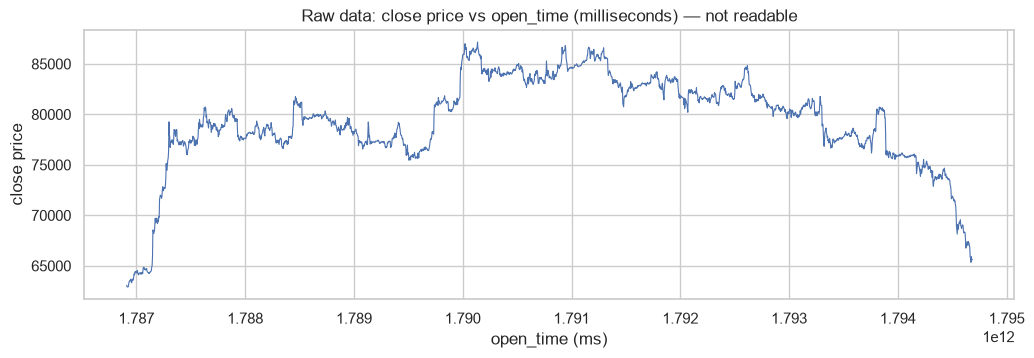

In [8]:
# Even to plot it, the price text must be converted. The x-axis is raw milliseconds.
fig, ax = plt.subplots(figsize=(12, 3.5))
ax.plot(raw["open_time"], raw["close"].astype(float), linewidth=0.8)
ax.set_title("Raw data: close price vs open_time (milliseconds) — not readable")
ax.set_xlabel("open_time (ms)")
ax.set_ylabel("close price")
plt.show()

Problems in the raw data:
- **Prices and volumes are text** — `raw.info()` shows them as `object`/`str`, not `float`.
- **Times are integers** — `open_time` and `close_time` are milliseconds since 1970, unreadable.
- **Extra columns** we don't need (`close_time`, taker volumes, `ignore`).
- **The last candle was still open at download time** — its close time is later than the download time (`still_open` is `True`), so its prices are a mid-hour snapshot, not final values.

## 3. Clean data

Each step is one small function, chained with `.pipe()`:
1. Drop the unfinished (still open) candle
2. Keep only the needed columns and give them readable names
3. Convert text → numbers and milliseconds → datetime
4. Remove duplicate candles and sort by time
5. Use `Time` (UTC) as the index

In [9]:
# The cleaning steps live in backend/app/market.py, shared with the backend.
# clean_klines: drop the unfinished candle -> keep and rename columns -> convert types -> remove duplicates
from app.market import FLOAT_COLUMNS, clean_klines


In [10]:
candles = clean_klines(raw, end)

print(f"Raw:   {raw.shape[0]:,} rows x {raw.shape[1]} columns")
print(f"Clean: {candles.shape[0]:,} rows x {candles.shape[1]} columns")
print(f"Period (UTC): {candles.index.min()} -> {candles.index.max()}")
candles.tail()

Raw:   2,160 rows x 12 columns
Clean: 2,159 rows x 7 columns
Period (UTC): 2026-08-16 20:00:00 -> 2026-11-14 18:00:00


,Open Price,High Price,Low Price,Close Price,Volume (BTC),Volume (USDT),Number of Trades
Time,,,,,,,
2026-11-14 14:00:00,"66,839.19","66,873.14","65,802.73","65,914.01","2,837.07","187,823,520.90",615082
2026-11-14 15:00:00,"65,914.02","66,047.37","65,066.66","65,742.01","3,041.27","199,277,996.24",644684
2026-11-14 16:00:00,"65,742.00","65,747.57","65,000.00","65,349.01","1,749.25","114,325,436.10",556879
2026-11-14 17:00:00,"65,349.00","66,189.88","65,070.32","65,901.60","1,284.51","84,251,087.76",427748
2026-11-14 18:00:00,"65,901.60","66,082.67","65,450.91","65,565.84",845.69,"55,647,243.01",333004


In [ ]:
candles.info()

### Quality checks

Before using the data, confirm it makes sense. `True` = check passed.

In [ ]:
def check_quality(df: pd.DataFrame, interval: str) -> pd.DataFrame:
    """Run sanity checks on candle data and return a pass/fail table."""
    expected_times = pd.date_range(df.index.min(), df.index.max(), freq=pd.Timedelta(interval))
    missing_times = expected_times.difference(df.index)
    body_low = df[["Open Price", "Close Price"]].min(axis=1)
    body_high = df[["Open Price", "Close Price"]].max(axis=1)

    problems = {
        "No empty values": int(df.isna().sum().sum()),
        "No duplicate times": int(df.index.duplicated().sum()),
        "No missing candles": len(missing_times),
        "High >= Low": int((df["High Price"] < df["Low Price"]).sum()),
        "Open/Close inside High-Low": int(((body_low < df["Low Price"]) | (body_high > df["High Price"])).sum()),
        "Prices above zero": int((df[FLOAT_COLUMNS[:4]] <= 0).any(axis=1).sum()),
        "Volume not negative": int((df["Volume (BTC)"] < 0).sum()),
    }
    report = pd.DataFrame({"Problem rows": problems})
    report.insert(0, "Passed", report["Problem rows"] == 0)
    return report


check_quality(candles, INTERVAL)

## 4. Visualize clean data

### 4.1 Candlestick + volume (interactive — zoom, pan, hover)
Green = price closed higher than it opened in that hour, red = lower.

In [11]:
def plot_candlestick(df: pd.DataFrame, title: str) -> go.Figure:
    """Interactive candlestick chart with a volume bar panel below."""
    fig = make_subplots(rows=2, cols=1, shared_xaxes=True,
                        row_heights=[0.65, 0.35], vertical_spacing=0.03)
    fig.add_trace(go.Candlestick(x=df.index,
                                 open=df["Open Price"], high=df["High Price"],
                                 low=df["Low Price"], close=df["Close Price"],
                                 name="Price"), row=1, col=1)
    colors = np.where(df["Close Price"] >= df["Open Price"], "#26a69a", "#ef5350")
    fig.add_trace(go.Bar(x=df.index, y=df["Volume (BTC)"],
                         marker_color=colors, marker_line_width=0,
                         name="Volume (BTC)"), row=2, col=1)
    fig.update_layout(title=title, height=650, template="plotly_white",
                      xaxis_rangeslider_visible=False, showlegend=False,
                      bargap=0)
    fig.update_yaxes(title_text="Price (USDT)", row=1, col=1)
    fig.update_yaxes(title_text="Volume (BTC)", row=2, col=1)
    return fig


plot_candlestick(candles, f"{SYMBOL} {INTERVAL} candles — last {LOOKBACK_DAYS} days").show()

### 4.2 Daily overview

Hourly candles grouped into days: close price with the day's high–low range, and daily traded volume.
The last day may be incomplete.

In [12]:
def to_daily(df: pd.DataFrame) -> pd.DataFrame:
    """Combine hourly candles into daily candles."""
    return df.resample("D").agg({
        "Open Price": "first",
        "High Price": "max",
        "Low Price": "min",
        "Close Price": "last",
        "Volume (BTC)": "sum",
        "Volume (USDT)": "sum",
        "Number of Trades": "sum",
    })


daily = to_daily(candles)
daily.tail()

,Open Price,High Price,Low Price,Close Price,Volume (BTC),Volume (USDT),Number of Trades
Time,,,,,,,
2026-11-10,"75,368.41","75,442.01","72,727.27","73,796.06","16,466.18","1,217,705,360.89",3895711
2026-11-11,"73,796.06","74,811.45","73,209.12","74,015.19","16,145.88","1,194,367,325.90",3704443
2026-11-12,"74,015.20","74,217.49","71,113.06","71,460.00","15,228.24","1,102,718,687.95",3537912
2026-11-13,"71,460.00","71,514.01","67,568.00","68,314.00","29,648.75","2,050,028,886.62",6226827
2026-11-14,"68,314.01","68,446.21","65,000.00","65,565.84","23,052.59","1,534,961,163.19",5577553


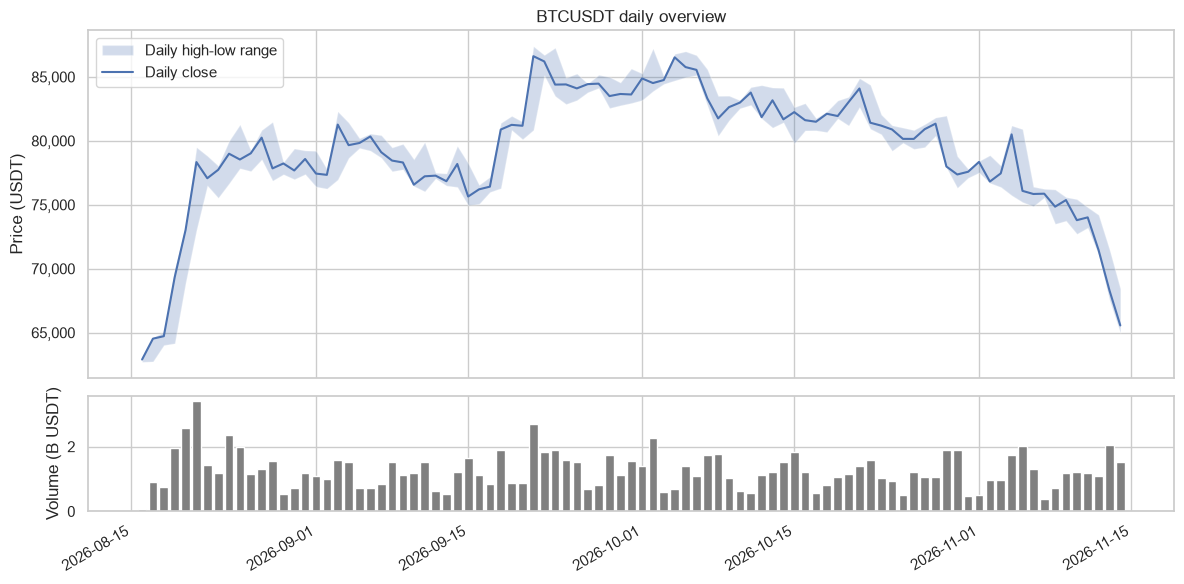

In [13]:
fig, (ax_price, ax_volume) = plt.subplots(2, 1, figsize=(12, 6), sharex=True,
                                          gridspec_kw={"height_ratios": [3, 1]})

ax_price.fill_between(daily.index, daily["Low Price"], daily["High Price"],
                      alpha=0.25, label="Daily high-low range")
ax_price.plot(daily.index, daily["Close Price"], linewidth=1.5, label="Daily close")
ax_price.set_title(f"{SYMBOL} daily overview")
ax_price.set_ylabel("Price (USDT)")
ax_price.yaxis.set_major_formatter(mticker.StrMethodFormatter("{x:,.0f}"))
ax_price.legend(loc="upper left")

ax_volume.bar(daily.index, daily["Volume (USDT)"] / 1e9, color="gray")
ax_volume.set_ylabel("Volume (B USDT)")

fig.autofmt_xdate()
plt.tight_layout()
plt.show()

### 4.3 Summary

In [ ]:
def summarize(df: pd.DataFrame) -> pd.DataFrame:
    """Key facts about the period as a one-column table."""
    first_close, last_close = df["Close Price"].iloc[0], df["Close Price"].iloc[-1]
    summary = {
        "From (UTC)": df.index.min(),
        "To (UTC)": df.index.max(),
        "Candles": f"{len(df):,}",
        "First close (USDT)": f"{first_close:,.2f}",
        "Last close (USDT)": f"{last_close:,.2f}",
        "Change": f"{last_close / first_close - 1:+.2%}",
        "Highest price (USDT)": f"{df['High Price'].max():,.2f} on {df['High Price'].idxmax()}",
        "Lowest price (USDT)": f"{df['Low Price'].min():,.2f} on {df['Low Price'].idxmin()}",
        "Total volume (BTC)": f"{df['Volume (BTC)'].sum():,.0f}",
        "Total volume (USDT)": f"{df['Volume (USDT)'].sum() / 1e9:,.1f} B",
        "Total trades": f"{df['Number of Trades'].sum():,}",
    }
    return pd.DataFrame({"Value": summary})


summarize(candles)

## 5. Indicators

A **simple moving average (SMA)** is the average close price of the last N candles. It smooths out the hour-to-hour noise.
- **Fast SMA** (short window) follows the price closely.
- **Slow SMA** (long window) shows the longer trend.

Trend-following strategies use the places where the two lines cross.

In [14]:
# Windows (backend/app/config.py) and the SMA function (backend/app/strategy.py) are shared with the backend
from app.config import FAST_WINDOW, SLOW_WINDOW
from app.strategy import FAST_COLUMN, SLOW_COLUMN, add_moving_averages

indicators = add_moving_averages(candles, FAST_WINDOW, SLOW_WINDOW)
indicators[["Close Price", FAST_COLUMN, SLOW_COLUMN]].tail()

,Close Price,Fast SMA (12),Slow SMA (48)
Time,,,
2026-11-14 14:00:00,"65,914.01","67,029.42","68,995.22"
2026-11-14 15:00:00,"65,742.01","66,944.95","68,870.89"
2026-11-14 16:00:00,"65,349.01","66,800.01","68,737.43"
2026-11-14 17:00:00,"65,901.60","66,688.37","68,612.32"
2026-11-14 18:00:00,"65,565.84","66,537.52","68,483.33"


In [15]:
def plot_with_averages(df: pd.DataFrame, title: str) -> go.Figure:
    """Interactive candlestick chart with the fast and slow SMA drawn over it."""
    fig = go.Figure()
    fig.add_trace(go.Candlestick(x=df.index,
                                 open=df["Open Price"], high=df["High Price"],
                                 low=df["Low Price"], close=df["Close Price"],
                                 increasing=dict(line=dict(color="rgba(38, 166, 154, 0.35)"),
                                                 fillcolor="rgba(38, 166, 154, 0.2)"),
                                 decreasing=dict(line=dict(color="rgba(239, 83, 80, 0.35)"),
                                                 fillcolor="rgba(239, 83, 80, 0.2)"),
                                 name="Price"))
    fig.add_trace(go.Scatter(x=df.index, y=df[FAST_COLUMN], name=FAST_COLUMN,
                             line=dict(color="black", width=2)))
    fig.add_trace(go.Scatter(x=df.index, y=df[SLOW_COLUMN], name=SLOW_COLUMN,
                             line=dict(color="#ff7f0e", width=2)))
    fig.update_layout(title=title, height=550, template="plotly_white",
                      xaxis_rangeslider_visible=False, yaxis_title="Price (USDT)",
                      legend=dict(orientation="h", y=1.05))
    return fig


plot_with_averages(indicators, f"{SYMBOL} {INTERVAL} with {FAST_COLUMN} and {SLOW_COLUMN}").show()

The first rows have no average yet: an SMA of N candles needs N candles of history, so the slow line starts later than the fast one.
When the fast line is above the slow line, the recent price is higher than the longer-term average (uptrend). When it is below, the opposite (downtrend). Each crossing marks a possible trend change.

## 6. Signals

Rules of the trend-following demo:
- **Buy** — the fast SMA crosses **above** the slow SMA (start of an uptrend).
- **Sell** — the fast SMA crosses **below** the slow SMA (start of a downtrend).

A crossing is known only when a candle closes, so each signal belongs to the candle on which the crossing happened.
`Trend` shows which line is on top for every candle; `Signal` is filled only on the candles where the trend flips.

In [16]:
# Trend and Buy/Sell signal logic: backend/app/strategy.py, shared with the backend
from app.strategy import BUY, SELL, add_signals

with_signals = add_signals(indicators)
signals = with_signals.loc[with_signals["Signal"] != "",
                           ["Close Price", FAST_COLUMN, SLOW_COLUMN, "Signal"]]
signals

,Close Price,Fast SMA (12),Slow SMA (48),Signal
Time,,,,
2026-08-23 00:00:00,"77,302.65","77,171.35","77,171.54",Sell
2026-08-23 21:00:00,"77,833.23","77,305.52","77,260.07",Buy
2026-08-26 02:00:00,"79,108.00","78,892.64","78,898.41",Sell
2026-08-27 07:00:00,"79,082.17","78,802.76","78,790.58",Buy
2026-08-28 16:00:00,"77,788.46","79,303.00","79,437.38",Sell
...,...,...,...,...
2026-11-07 18:00:00,"75,802.58","75,938.30","75,942.49",Sell
2026-11-08 13:00:00,"75,930.02","75,905.75","75,894.00",Buy
2026-11-08 21:00:00,"74,135.77","75,765.43","75,866.88",Sell


In [17]:
def summarize_signals(signals: pd.DataFrame, df: pd.DataFrame) -> pd.DataFrame:
    """How many signals there are and how often they come, as a one-column table."""
    days = (df.index.max() - df.index.min()) / pd.Timedelta(days=1)
    gaps = signals.index.to_series().diff().dropna()
    summary = {
        "Buy signals": int((signals["Signal"] == BUY).sum()),
        "Sell signals": int((signals["Signal"] == SELL).sum()),
        "Signals per day": f"{len(signals) / days:.2f}",
        "Shortest gap between signals": gaps.min(),
        "Typical (median) gap": gaps.median(),
        "Longest gap between signals": gaps.max(),
    }
    return pd.DataFrame({"Value": summary})


summarize_signals(signals, with_signals)

,Value
Buy signals,33
Sell signals,34
Signals per day,0.75
Shortest gap between signals,0 days 01:00:00
Typical (median) gap,1 days 04:00:00
Longest gap between signals,5 days 09:00:00


In [18]:
def plot_signals(df: pd.DataFrame, title: str) -> go.Figure:
    """Candlestick chart with both SMAs and a marker on every Buy and Sell candle."""
    fig = plot_with_averages(df, title)
    for signal, symbol, color in [(BUY, "triangle-up", "#1a9850"),
                                  (SELL, "triangle-down", "#d73027")]:
        points = df[df["Signal"] == signal]
        fig.add_trace(go.Scatter(x=points.index, y=points["Close Price"], mode="markers",
                                 name=signal, marker=dict(symbol=symbol, size=12, color=color,
                                                          line=dict(color="black", width=1))))
    return fig


plot_signals(with_signals, f"{SYMBOL} {INTERVAL} — Buy and Sell signals ({FAST_COLUMN} / {SLOW_COLUMN})").show()

Buy and Sell always alternate: after the fast line crosses above, the next crossing can only be downward.
In strong trends the signals are far apart. In sideways markets the two lines stay close and cross back and forth, so signals come in quick pairs — these are the false signals (whipsaws) that make a trend-following strategy lose small amounts.
The signal is known at the close of its candle, so a trade based on it can happen at the earliest at the open of the next candle.

## 7. Backtest

The signals replayed on the downloaded history, as if the bot had traded them:
- **Long only** — Binance spot cannot short, so a Buy opens a position and a Sell closes it. A Sell with no open position is skipped.
- **Fixed size** — every Buy spends the same small amount of USDT.
- **Fill price** — the open of the candle after the signal (the signal is known only at the close).
- **Fees** — Binance spot fee on both the buy and the sell.
- A position still open at the end is valued at the last close, as if sold then.

In [22]:
from app.config import FEE_RATE, TRADE_SIZE_USDT   # backend/app/config.py: 100 USDT per Buy, 0.1% fee on each order

CLOSED, OPEN = "Closed", "Open"


def open_trade(time: pd.Timestamp, price: float) -> dict:
    """A new position bought for TRADE_SIZE_USDT; the fee is paid out of the amount."""
    quantity = TRADE_SIZE_USDT * (1 - FEE_RATE) / price
    return {"Entry Time": time, "Entry Price": price,
            "Spent (USDT)": TRADE_SIZE_USDT, "Quantity (BTC)": quantity}


def close_trade(entry: dict, time: pd.Timestamp, price: float, status: str) -> dict:
    """Complete a trade record: exit, money received, fees, profit and holding time."""
    sale = entry["Quantity (BTC)"] * price
    received = sale * (1 - FEE_RATE)
    fees = TRADE_SIZE_USDT * FEE_RATE + sale * FEE_RATE
    profit = received - TRADE_SIZE_USDT
    return {**entry, "Exit Time": time, "Exit Price": price,
            "Received (USDT)": received, "Fees (USDT)": fees, "Profit (USDT)": profit,
            "Return (%)": profit / TRADE_SIZE_USDT * 100,
            "Held": time - entry["Entry Time"], "Status": status}


def run_backtest(df: pd.DataFrame) -> pd.DataFrame:
    """Replay the Buy/Sell signals and return one row per trade."""
    next_open = df["Open Price"].shift(-1)
    next_time = df.index.to_series().shift(-1)
    trades, entry = [], None

    for time, signal in df.loc[df["Signal"] != "", "Signal"].items():
        if pd.isna(next_time[time]):          # signal on the last candle: no next candle to fill on
            continue
        if signal == BUY and entry is None:
            entry = open_trade(next_time[time], next_open[time])
        elif signal == SELL and entry is not None:
            trades.append(close_trade(entry, next_time[time], next_open[time], CLOSED))
            entry = None

    if entry is not None:
        trades.append(close_trade(entry, df.index[-1], df["Close Price"].iloc[-1], OPEN))
    return pd.DataFrame(trades)


def show_trades(trades: pd.DataFrame) -> pd.DataFrame:
    """Trades table for display: BTC quantity with 6 decimals (2 decimals would show 0.00)."""
    return trades.assign(**{"Quantity (BTC)": trades["Quantity (BTC)"].map("{:.6f}".format)})


trades = run_backtest(with_signals)
show_trades(trades)

,Entry Time,Entry Price,Spent (USDT),Quantity (BTC),Exit Time,Exit Price,Received (USDT),Fees (USDT),Profit (USDT),Return (%),Held,Status
0,2026-08-23 22:00:00,"77,833.23",100.00,0.001284,2026-08-26 03:00:00,"79,108.01",101.43,0.20,1.43,1.43,2 days 05:00:00,Closed
1,2026-08-27 08:00:00,"79,082.18",100.00,0.001263,2026-08-28 17:00:00,"77,788.45",98.17,0.20,-1.83,-1.83,1 days 09:00:00,Closed
2,2026-08-30 07:00:00,"78,280.34",100.00,0.001276,2026-08-31 06:00:00,"78,016.01",99.46,0.20,-0.54,-0.54,0 days 23:00:00,Closed
3,2026-08-31 17:00:00,"78,639.57",100.00,0.001270,2026-09-01 12:00:00,"78,098.96",99.11,0.20,-0.89,-0.89,0 days 19:00:00,Closed
4,2026-09-03 07:00:00,"77,835.20",100.00,0.001283,2026-09-04 23:00:00,"79,636.09",102.11,0.20,2.11,2.11,1 days 16:00:00,Closed
5,2026-09-06 04:00:00,"80,028.01",100.00,0.001248,2026-09-07 09:00:00,"79,437.39",99.06,0.20,-0.94,-0.94,1 days 05:00:00,Closed
6,2026-09-09 09:00:00,"79,698.02",100.00,0.001253,2026-09-09 23:00:00,"77,924.00",97.58,0.20,-2.42,-2.42,0 days 14:00:00,Closed
7,2026-09-11 18:00:00,"77,534.00",100.00,0.001288,2026-09-12 02:00:00,"77,272.36",99.46,0.20,-0.54,-0.54,0 days 08:00:00,Closed
8,2026-09-12 15:00:00,"77,461.25",100.00,0.001290,2026-09-12 20:00:00,"77,115.00",99.35,0.20,-0.65,-0.65,0 days 05:00:00,Closed
9,2026-09-14 04:00:00,"77,596.32",100.00,0.001287,2026-09-15 10:00:00,"76,984.05",99.01,0.20,-0.99,-0.99,1 days 06:00:00,Closed


In [23]:
def summarize_backtest(trades: pd.DataFrame, df: pd.DataFrame) -> pd.DataFrame:
    """Key results of the backtest as a one-column table."""
    closed = trades[trades["Status"] == CLOSED]
    days = (df.index.max() - df.index.min()) / pd.Timedelta(days=1)
    wins = int((closed["Profit (USDT)"] > 0).sum())
    summary = {
        "Trade size (USDT)": f"{TRADE_SIZE_USDT:,.2f}",
        "Closed trades": len(closed),
        "Position open at the end": "Yes" if (trades["Status"] == OPEN).any() else "No",
        "Trades per day": f"{len(closed) / days:.2f}",
        "Winning trades": wins,
        "Losing trades": len(closed) - wins,
        "Win rate": f"{wins / len(closed):.0%}" if len(closed) else "-",
        "Best trade (USDT)": f"{trades['Profit (USDT)'].max():+,.2f}",
        "Worst trade (USDT)": f"{trades['Profit (USDT)'].min():+,.2f}",
        "Total fees (USDT)": f"{trades['Fees (USDT)'].sum():,.2f}",
        "Total profit after fees (USDT)": f"{trades['Profit (USDT)'].sum():+,.2f}",
        "Typical (median) holding time": trades["Held"].median(),
    }
    return pd.DataFrame({"Value": summary})


summarize_backtest(trades, with_signals)

,Value
Trade size (USDT),100.00
Closed trades,33
Position open at the end,No
Trades per day,0.37
Winning trades,6
Losing trades,27
Win rate,18%
Best trade (USDT),+4.94
Worst trade (USDT),-2.56
Total fees (USDT),6.58


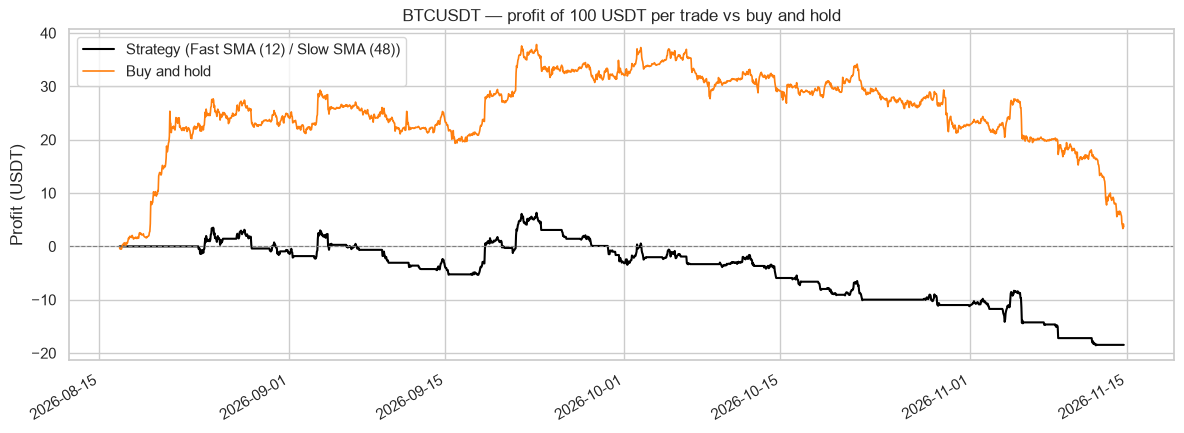

In [24]:
def strategy_profit_curve(df: pd.DataFrame, trades: pd.DataFrame) -> pd.Series:
    """Profit of the strategy at every candle: closed trades plus the open position valued at the close."""
    profit = pd.Series(0.0, index=df.index)
    for _, trade in trades.iterrows():
        holding = (df.index >= trade["Entry Time"]) & (df.index < trade["Exit Time"])
        value_now = trade["Quantity (BTC)"] * df["Close Price"] * (1 - FEE_RATE) - TRADE_SIZE_USDT
        profit[holding] += value_now[holding]
        profit[df.index >= trade["Exit Time"]] += trade["Profit (USDT)"]
    return profit


def buy_and_hold_curve(df: pd.DataFrame) -> pd.Series:
    """Profit of buying TRADE_SIZE_USDT of BTC at the first candle and holding it to the end."""
    quantity = TRADE_SIZE_USDT * (1 - FEE_RATE) / df["Open Price"].iloc[0]
    return quantity * df["Close Price"] * (1 - FEE_RATE) - TRADE_SIZE_USDT


strategy_curve = strategy_profit_curve(with_signals, trades)
hold_curve = buy_and_hold_curve(with_signals)

fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(strategy_curve.index, strategy_curve, color="black", linewidth=1.5,
        label=f"Strategy ({FAST_COLUMN} / {SLOW_COLUMN})")
ax.plot(hold_curve.index, hold_curve, color="#ff7f0e", linewidth=1.2, label="Buy and hold")
ax.axhline(0, color="gray", linewidth=0.8, linestyle="--")
ax.set_title(f"{SYMBOL} — profit of {TRADE_SIZE_USDT:,.0f} USDT per trade vs buy and hold")
ax.set_ylabel("Profit (USDT)")
ax.legend(loc="upper left")
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

The trade table shows each round trip from Buy to Sell. Whipsaws appear as short trades with small losses, and most of the fees come from them.
The profit chart compares the strategy with simply holding BTC: the strategy is out of the market during downtrends, so it loses less when the price falls and misses part of the move when the price rises.
Limits of this backtest: no slippage (the real fill price can be slightly worse), only one 90-day window, and past results do not predict future ones. The goal of the demo is a visible trade history, not profit.

## 8. Testnet connection

**Binance Spot Testnet** (`testnet.binance.vision`) has the same API as the real exchange, but the money is fake — orders and balances there cost nothing.
- The keys come from `.env` (`BINANCE_TESTNET_API_KEY`, `BINANCE_TESTNET_SECRET_KEY`). Their values are never printed.
- Private requests are signed with a timestamp, and Binance rejects them if this computer's clock differs too much from the server's, so the clock difference is part of the check.

In [25]:
from binance.client import Client

from app.exchange import connect_testnet   # backend/app/exchange.py: testnet client from the keys in .env


def check_clock(client: Client) -> pd.DataFrame:
    """Binance server time next to this computer's time, both in UTC."""
    server = pd.Timestamp(client.get_server_time()["serverTime"], unit="ms")
    local = pd.Timestamp(datetime.now(timezone.utc)).tz_localize(None)
    summary = {
        "Connected to": client.API_TESTNET_URL,
        "Binance server time (UTC)": server,
        "This computer (UTC)": local,
        "Difference (seconds)": f"{(local - server).total_seconds():+.3f}",
    }
    return pd.DataFrame({"Value": summary})


client = connect_testnet()
check_clock(client)

,Value
Connected to,https://testnet.binance.vision/api
Binance server time (UTC),2026-11-14 20:19:21.295000
This computer (UTC),2026-11-14 20:19:21.456349
Difference (seconds),+0.161


In [26]:
from app.bot import format_amount
from app.exchange import get_symbol_rules


def get_balances(client: Client, assets: list[str]) -> pd.DataFrame:
    """Available and locked amounts of the given assets in the testnet account."""
    balances = pd.DataFrame(client.get_account()["balances"]).set_index("asset")
    table = (balances[["free", "locked"]].astype(float)
             .reindex(assets, fill_value=0.0)
             .rename(columns={"free": "Available", "locked": "Locked (in open orders)"}))
    table.index.name = "Asset"
    return table.map(format_amount)


rules = get_symbol_rules(client, SYMBOL)   # base/quote asset and the allowed quantity step
BASE_ASSET, QUOTE_ASSET = rules.base_asset, rules.quote_asset   # BTC, USDT
get_balances(client, [BASE_ASSET, QUOTE_ASSET])

,Available,Locked (in open orders)
Asset,,
BTC,1.10718,0
USDT,"2,093.5189992",0


In [29]:
PLACE_TEST_ORDER = False   # True sends one market buy to the testnet (fake money)


from app.exchange import place_market_buy   # backend/app/exchange.py


def summarize_order(order: dict) -> pd.DataFrame:
    """Key facts of a filled order as a one-column table."""
    quantity = float(order["executedQty"])
    spent = float(order["cummulativeQuoteQty"])
    fees = (pd.DataFrame(order["fills"])
            .assign(commission=lambda f: f["commission"].astype(float))
            .groupby("commissionAsset")["commission"].sum())
    summary = {
        "Order ID": order["orderId"],
        "Status": order["status"],
        "Time (UTC)": pd.Timestamp(order["transactTime"], unit="ms"),
        f"Spent ({QUOTE_ASSET})": format_amount(spent),
        f"Quantity ({BASE_ASSET})": format_amount(quantity),
        f"Average price ({QUOTE_ASSET})": f"{spent / quantity:,.2f}",
        "Fee": ", ".join(f"{format_amount(amount)} {asset}" for asset, amount in fees.items()),
        "Number of fills": len(order["fills"]),
    }
    return pd.DataFrame({"Value": summary})


if PLACE_TEST_ORDER:
    order = place_market_buy(client, SYMBOL, TRADE_SIZE_USDT)
    display(summarize_order(order))
else:
    order = None
    print(f"PLACE_TEST_ORDER is False — no order sent. "
          f"With True: market buy of {TRADE_SIZE_USDT:,.2f} {QUOTE_ASSET} of {SYMBOL} on the testnet.")

PLACE_TEST_ORDER is False — no order sent. With True: market buy of 100.00 USDT of BTCUSDT on the testnet.


In [30]:
# Balances after the order (unchanged when no order was sent)
get_balances(client, [BASE_ASSET, QUOTE_ASSET])

,Available,Locked (in open orders)
Asset,,
BTC,1.1087,0
USDT,"1,993.9014368",0


A market buy fills immediately at the best prices in the testnet order book. A large order can fill at several prices, which shows as more than one fill.
The testnet has its own order book, so its prices can differ from the real market used in sections 1–7. Testnet balances are fake and Binance resets them from time to time.
When the fee is charged in BTC, the BTC balance grows by slightly less than the bought quantity.

## 9. Live bot (testnet)

The strategy from sections 5–7 running on live data. Every hour, a few seconds after a candle closes:
1. The latest candles come from the real market (the same source as sections 1–7); the still-open candle is dropped.
2. The SMAs and the signal are computed with the same functions as before; only the **last closed candle** counts.
3. Long only, like the backtest: **Buy** signal and no position → market buy of `TRADE_SIZE_USDT` on the testnet; **Sell** signal and a position → market sell of the BTC the bot bought; anything else → no order.
4. One line per hour shows the candle, the averages, the trend, the signal and the action.

Settings:
- `DRY_RUN` — `True`: the bot decides and logs, but sends no orders (fills are estimated at the close price). `False`: real testnet orders.
- `RUN_HOURS` — the loop stops by itself after this many hours. The notebook's Stop button ends it earlier.

Position memory: every order goes into a CSV file in `logs/` (a separate file for dry runs). After a restart the bot reads it and knows whether it still holds BTC. The testnet account itself starts with fake BTC, so its balance cannot show that.
The loop occupies the notebook while it runs, and it runs only while this computer and the notebook are on.

In [31]:
from pathlib import Path

from binance.exceptions import BinanceAPIException, BinanceRequestException

DRY_RUN = False              # True: decide and log only; False: send real orders to the testnet
RUN_HOURS = 24              # the loop stops by itself after this many hours
CHECK_DELAY_SECONDS = 10    # wait after each candle close so Binance has finished the candle

LOG_DIR = Path("../../logs")   # project-root logs/ (this notebook runs from backend/notebooks/)
LOG_FILE = LOG_DIR / ("dry_run_orders.csv" if DRY_RUN else "testnet_orders.csv")
QUANTITY_COLUMN = f"Quantity ({BASE_ASSET})"
AMOUNT_COLUMN = f"Amount ({QUOTE_ASSET})"
PRICE_COLUMN = f"Average price ({QUOTE_ASSET})"
LOG_COLUMNS = ["Time (UTC)", "Side", "Order ID", "Status",
               QUANTITY_COLUMN, AMOUNT_COLUMN, PRICE_COLUMN, "Fee", "Fee asset"]
print(f"Mode: {'DRY RUN (no orders)' if DRY_RUN else 'TESTNET ORDERS'} | log file: {LOG_FILE}")

Mode: TESTNET ORDERS | log file: logs/testnet_orders.csv


In [32]:
from app.exchange import place_market_sell      # backend/app/exchange.py: rounds to the lot step, then sells
from app.strategy import latest_closed_candle   # backend/app/strategy.py: last closed candle with SMAs, trend, signal


def record_from_order(order: dict, side: str) -> dict:
    """Log row from a filled Binance order."""
    fills = order.get("fills", [])
    quantity = float(order["executedQty"])
    amount = float(order["cummulativeQuoteQty"])
    return {"Time (UTC)": pd.Timestamp(order["transactTime"], unit="ms"), "Side": side,
            "Order ID": order["orderId"], "Status": order["status"],
            QUANTITY_COLUMN: quantity, AMOUNT_COLUMN: amount, PRICE_COLUMN: amount / quantity,
            "Fee": sum(float(f["commission"]) for f in fills),
            "Fee asset": fills[0]["commissionAsset"] if fills else ""}


def simulated_record(side: str, quantity: float, price: float) -> dict:
    """Log row for a dry run: filled at the given price, fee estimated in the quote asset."""
    amount = quantity * price
    return {"Time (UTC)": pd.Timestamp.now(tz="UTC").tz_localize(None), "Side": side,
            "Order ID": "dry-run", "Status": "SIMULATED",
            QUANTITY_COLUMN: quantity, AMOUNT_COLUMN: amount, PRICE_COLUMN: price,
            "Fee": amount * FEE_RATE, "Fee asset": QUOTE_ASSET}


def buy(price: float) -> dict:
    """Market buy of TRADE_SIZE_USDT (simulated at price in a dry run)."""
    if DRY_RUN:
        return simulated_record("BUY", TRADE_SIZE_USDT / price, price)
    return record_from_order(place_market_buy(client, SYMBOL, TRADE_SIZE_USDT), "BUY")


def sell(quantity: float, price: float) -> dict:
    """Market sell of the held quantity, rounded down to the allowed step."""
    if DRY_RUN:
        return simulated_record("SELL", quantity, price)
    order = place_market_sell(client, rules, quantity)
    return record_from_order(order, "SELL")


def load_log() -> pd.DataFrame:
    """All orders the bot logged so far (empty table before the first one)."""
    if not LOG_FILE.exists():
        return pd.DataFrame(columns=LOG_COLUMNS)
    return pd.read_csv(LOG_FILE, parse_dates=["Time (UTC)"])


def append_log(record: dict) -> None:
    """Add one order to the log file."""
    LOG_DIR.mkdir(exist_ok=True)
    pd.DataFrame([record], columns=LOG_COLUMNS).to_csv(
        LOG_FILE, mode="a", header=not LOG_FILE.exists(), index=False)


def held_quantity(log: pd.DataFrame) -> float:
    """BTC the bot holds: the last Buy's quantity (minus a fee paid in BTC) if no Sell came after it."""
    if log.empty or log["Side"].iloc[-1] != "BUY":
        return 0.0
    last = log.iloc[-1]
    fee_in_base = last["Fee"] if last["Fee asset"] == BASE_ASSET else 0.0
    return float(last[QUANTITY_COLUMN] - fee_in_base)


def run_cycle() -> str:
    """One check: latest signal, an order if the rules call for one, and a status line."""
    candle = latest_closed_candle(SYMBOL, INTERVAL)
    held = held_quantity(load_log())
    signal, close = candle["Signal"], candle["Close Price"]

    if signal == BUY and held == 0:
        record = buy(close)
        action = f"BUY {format_amount(record[QUANTITY_COLUMN])} {BASE_ASSET} for {record[AMOUNT_COLUMN]:,.2f} {QUOTE_ASSET}"
    elif signal == SELL and held > 0:
        record = sell(held, close)
        action = f"SELL {format_amount(record[QUANTITY_COLUMN])} {BASE_ASSET} for {record[AMOUNT_COLUMN]:,.2f} {QUOTE_ASSET}"
    else:
        record = None
        position = f"holding {format_amount(held)} {BASE_ASSET}" if held else "no position"
        action = f"no order ({position})"

    if record:
        append_log(record)
    return (f"candle {candle.name:%Y-%m-%d %H:%M} | close {close:,.2f} | "
            f"fast {candle[FAST_COLUMN]:,.2f} | slow {candle[SLOW_COLUMN]:,.2f} | "
            f"trend {candle['Trend'] or '-'} | signal {signal or '-'} | {action}")


def seconds_until_next_check() -> float:
    """Seconds until the next candle closes, plus CHECK_DELAY_SECONDS."""
    now = pd.Timestamp.now(tz="UTC")
    interval = pd.Timedelta(INTERVAL)
    next_check = now.floor(interval) + interval + pd.Timedelta(seconds=CHECK_DELAY_SECONDS)
    return (next_check - now).total_seconds()


LOT_STEP = rules.lot_step
print(f"Allowed quantity step for {SYMBOL}: {LOT_STEP.normalize():f} {BASE_ASSET}")
print(f"Position from the log: {format_amount(held_quantity(load_log()))} {BASE_ASSET}")

Allowed quantity step for BTCUSDT: 0.00001 BTC
Position from the log: 0 BTC


In [33]:
def run_bot() -> pd.Timestamp:
    """Check once now, then after every candle close, until RUN_HOURS pass or the Stop button is pressed."""
    started = pd.Timestamp.now(tz="UTC")
    stop_at = started + pd.Timedelta(hours=RUN_HOURS)
    mode = "DRY RUN (no orders)" if DRY_RUN else "TESTNET ORDERS"
    print(f"Bot started {started:%Y-%m-%d %H:%M:%S} UTC | {mode} | stops at {stop_at:%Y-%m-%d %H:%M} UTC")
    try:
        while pd.Timestamp.now(tz="UTC") < stop_at:
            try:
                print(run_cycle(), flush=True)
            except (requests.RequestException, BinanceAPIException, BinanceRequestException) as error:
                print(f"{pd.Timestamp.now(tz='UTC'):%Y-%m-%d %H:%M:%S} | error, next try at the next check: {error}",
                      flush=True)
            remaining = (stop_at - pd.Timestamp.now(tz="UTC")).total_seconds()
            time.sleep(max(0.0, min(seconds_until_next_check(), remaining)))
        print("Run time over (RUN_HOURS reached).")
    except KeyboardInterrupt:
        print("Stopped with the Stop button.")
    return started


run_started = run_bot()

Bot started 2026-11-14 20:28:52 UTC | TESTNET ORDERS | stops at 2026-11-15 20:28 UTC
candle 2026-11-14 19:00 | close 65,727.61 | fast 66,417.71 | slow 68,359.18 | trend Down | signal - | no order (no position)
Stopped with the Stop button.


In [34]:
def orders_since(start: pd.Timestamp) -> pd.DataFrame:
    """Orders logged since start, with the BTC quantity shown in full."""
    log = load_log()
    run = log[log["Time (UTC)"] >= start.tz_localize(None)]
    return run.assign(**{QUANTITY_COLUMN: run[QUANTITY_COLUMN].map(format_amount)})


run_orders = orders_since(run_started)
print(f"Orders in this run: {len(run_orders)} | log file: {LOG_FILE}")
run_orders

Orders in this run: 0 | log file: logs/testnet_orders.csv


,Time (UTC),Side,Order ID,Status,Quantity (BTC),Amount (USDT),Average price (USDT),Fee,Fee asset


Most hourly lines end with "no order": signals come only when the averages cross, about once every one to two days in the backtest.
Each line uses the candle that has just closed, so the time shown is that candle's open time — one interval before the moment of the check.
A dry run shows the decisions without touching the account; its fills are estimates at the close price. With `DRY_RUN = False` the log holds the real testnet fills, prices and fees.
The log file stays between runs, so the next run continues with the same position.